

The motive of the project "Prediction of Remaining Useful Life for AeroEngines using ML" is to predict how much time or usage is left before an aeroengine will fail or need maintenance.

In simple words, we are detecting the health condition of the engine and estimating its remaining lifespan so that failures can be prevented, safety can be ensured, and maintenance can be done at the right time.

👉 So the main goal: Detect early signs of engine degradation and predict when the engine will stop working properly.

An aero engine means an aircraft engine — the power unit that provides thrust to an airplane so it can fly.

It is usually a jet engine or turbofan engine that works by taking in air, compressing it, mixing it with fuel, igniting it, and then expelling it at high speed to push the aircraft forward.

👉 In short: An aero engine is simply the engine of an aircraft that generates power or thrust for flight

# Importing Neccessary Libraries


In [1]:
import numpy as np
import pandas as pd

In [2]:
import pandas as pd

# Step 1: Load the dataset from the text file
file_path = 'NASA_Aeroengine_RUL_dataset.csv'

# Read the file, assuming the columns are separated by a semicolon (`;`)
data = pd.read_csv(file_path)




# # Data collection

In [3]:
import pandas as pd

# Step 1: Load the dataset from the text file
file_path = 'NASA_Aeroengine_RUL_dataset.csv'

# Read the file, assuming the columns are separated by a semicolon (`;`)
df = pd.read_csv(file_path)




In [6]:
df.head()

,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,52,271,1.092798,1.039463,0.862407,0.857993,0.768476,1.049654,0.815494,0.801035,...,0.754251,0.955318,0.881034,0.682207,1.092362,0.774256,0.844175,1.082853,1.039671,31
1,78,215,1.008334,1.184469,1.137814,0.796134,0.751086,0.751646,0.610282,0.552149,...,0.726584,0.685523,0.766121,0.636418,0.685950,0.554181,0.715921,0.628169,0.782864,83
2,94,231,0.964153,1.102220,0.891519,0.599285,0.877259,0.910671,0.879969,0.678317,...,0.711921,0.795990,0.845407,0.908711,0.597610,0.702405,0.630373,0.755018,0.692205,65
3,53,172,0.979113,1.021157,1.037079,0.492286,0.579832,0.535569,0.745101,0.622281,...,0.616698,0.586952,0.657788,0.580290,0.686164,0.550184,0.599593,0.701084,0.642477,123
4,72,104,1.042572,0.803679,0.840589,0.462628,0.391430,0.259698,0.361810,0.429016,...,0.376912,0.273409,0.227161,0.431867,0.398438,0.315177,0.429722,0.407314,0.353278,197


In [7]:
df.shape

(10000, 27)

In [8]:
df.tail()

,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
9995,81,283,0.953127,0.960746,0.853637,0.889674,0.783304,0.777623,0.968299,0.960573,...,0.792641,1.016958,0.995926,0.835815,0.765412,0.806070,0.932996,0.903786,0.885966,21
9996,9,277,0.977724,1.105434,0.820521,0.958391,1.152658,0.941835,1.097058,1.014611,...,0.983981,0.961138,1.071792,0.993323,1.037017,0.975138,0.808699,0.836168,0.916015,18
9997,47,105,0.906125,1.177060,0.978726,0.363211,0.392886,0.411216,0.402639,0.415550,...,0.352883,0.232544,0.361859,0.328473,0.386472,0.354427,0.349322,0.328266,0.283240,195
9998,81,192,0.805498,1.138798,1.131145,0.701554,0.564396,0.605599,0.640117,0.736276,...,0.498045,0.579373,0.694291,0.606319,0.464207,0.610439,0.684586,0.680428,0.636786,103
9999,32,168,1.149241,0.985688,0.888937,0.677848,0.662365,0.524135,0.447920,0.481733,...,0.514118,0.617646,0.462826,0.583437,0.510954,0.448091,0.577264,0.552578,0.709284,136


In [9]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing values in each column:\n", missing_values)

Missing values in each column:
 engine_id       0
cycle           0
op_setting_1    0
op_setting_2    0
op_setting_3    0
sensor_1        0
sensor_2        0
sensor_3        0
sensor_4        0
sensor_5        0
sensor_6        0
sensor_7        0
sensor_8        0
sensor_9        0
sensor_10       0
sensor_11       0
sensor_12       0
sensor_13       0
sensor_14       0
sensor_15       0
sensor_16       0
sensor_17       0
sensor_18       0
sensor_19       0
sensor_20       0
sensor_21       0
RUL             0
dtype: int64


In [10]:
df.dtypes

engine_id         int64
cycle             int64
op_setting_1    float64
op_setting_2    float64
op_setting_3    float64
sensor_1        float64
sensor_2        float64
sensor_3        float64
sensor_4        float64
sensor_5        float64
sensor_6        float64
sensor_7        float64
sensor_8        float64
sensor_9        float64
sensor_10       float64
sensor_11       float64
sensor_12       float64
sensor_13       float64
sensor_14       float64
sensor_15       float64
sensor_16       float64
sensor_17       float64
sensor_18       float64
sensor_19       float64
sensor_20       float64
sensor_21       float64
RUL               int64
dtype: object

# # Data Pre-processing

In [4]:
df.isnull().sum()

engine_id       0
cycle           0
op_setting_1    0
op_setting_2    0
op_setting_3    0
sensor_1        0
sensor_2        0
sensor_3        0
sensor_4        0
sensor_5        0
sensor_6        0
sensor_7        0
sensor_8        0
sensor_9        0
sensor_10       0
sensor_11       0
sensor_12       0
sensor_13       0
sensor_14       0
sensor_15       0
sensor_16       0
sensor_17       0
sensor_18       0
sensor_19       0
sensor_20       0
sensor_21       0
RUL             0
dtype: int64

In [12]:
df.describe()

,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,50.58410,150.177200,0.999446,1.000384,1.000813,0.499567,0.500640,0.501814,0.500291,0.500124,...,0.499725,0.499842,0.501652,0.500109,0.500992,0.499879,0.501547,0.501075,0.500435,149.816200
std,28.82001,86.048333,0.115701,0.115741,0.115759,0.298538,0.298599,0.300418,0.297976,0.299232,...,0.298534,0.298348,0.298182,0.298922,0.298841,0.299662,0.299068,0.299264,0.298147,86.129586
min,1.00000,1.000000,0.800004,0.800060,0.800028,-0.125985,-0.125440,-0.117192,-0.167400,-0.131599,...,-0.142542,-0.119985,-0.123546,-0.118171,-0.132477,-0.133313,-0.125221,-0.109909,-0.141680,1.000000
25%,26.00000,76.000000,0.898634,0.900858,0.901761,0.248831,0.247690,0.252386,0.249527,0.250485,...,0.252249,0.246954,0.252550,0.251257,0.250981,0.245772,0.251696,0.249575,0.249668,76.000000
50%,50.00000,150.000000,0.999722,1.000485,0.999196,0.492909,0.497473,0.495318,0.495567,0.494402,...,0.492462,0.495095,0.493081,0.492746,0.494188,0.494998,0.494049,0.498344,0.496156,150.000000
75%,75.00000,224.000000,1.099475,1.101036,1.100727,0.735785,0.736192,0.740778,0.735988,0.739739,...,0.739162,0.735138,0.739695,0.738272,0.737637,0.737641,0.735676,0.736192,0.737006,224.000000
max,100.00000,300.000000,1.199990,1.199955,1.199978,1.297144,1.298901,1.306830,1.254614,1.265256,...,1.303542,1.225808,1.282000,1.270446,1.294223,1.252774,1.246627,1.321854,1.303977,304.000000


In [4]:
from skimpy import skim
skim(df)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 10000  │ │ float64     │ 24    │                                                          │
│ │ Number of columns │ 27     │ │ int32       │ 3     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━┳━━━━━━━━┓  │
│ ┃ column         ┃ NA  ┃ NA %  ┃ mean    ┃ sd      ┃ p0       ┃ p25     ┃ p50     ┃ p75     ┃ p100  ┃ hist   ┃  │
│ ┡━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━╇━━━━━━━━┩  │
│ │ engine_id      │   0 │     0 │   50.58 │   28.82 │        1 │      26 │      50 │      75 │   100 │ ▇▇▇▇▇▇ │  │
│ │ cycle          │   0 │     0 │   150.2 │   86.05 │        1 │      76 │     150 │     224 │   300 │ ▇▇▇▇▇▇ │  │
│ │ op_setting_1   │   0 │     0 │  0.9994 │  0.1157 │      0.8 │  0.8986 │  0.9997 │   1.099 │   1.2 │ ▇▇▇▇▇▇ │  │
│ │ op_setting_2   │   0 │     0 │       1 │  0.1157 │   0.8001 │  0.9009 │       1 │   1.101 │   1.2 │ ▇▇▇▇▇▇ │  │
│ │ op_setting_3   │   0 │     0 │   1.001 │  0.1158 │      0.8 │  0.9018 │  0.9992 │   1.101 │   1.2 │ ▇▇▇▇▇▇ │  │
│ │ sensor_1       │   0 │     0 │  0.4996 │  0.2985 │   -0.126 │  0.2488 │  0.4929 │  0.7358 │ 1.297 │ ▃▇▇▇▅▁ │  │
│ │ sensor_2       │   0 │     0 │  0.5006 │  0.2986 │  -0.1254 │  0.2477 │  0.4975 │  0.7362 │ 1.299 │ ▃▇▇▇▅▁ │  │
│ │ sensor_3       │   0 │     0 │  0.5018 │  0.3004 │  -0.1172 │  0.2524 │  0.4953 │  0.7408 │ 1.307 │ ▃▇▇▇▅▁ │  │
│ │ sensor_4       │   0 │     0 │  0.5003 │   0.298 │  -0.1674 │  0.2495 │  0.4956 │   0.736 │ 1.255 │ ▂▇▇▇▅▁ │  │
│ │ sensor_5       │   0 │     0 │  0.5001 │  0.2992 │  -0.1316 │  0.2505 │  0.4944 │  0.7397 │ 1.265 │ ▃▇▇▇▅▁ │  │
│ │ sensor_6       │   0 │     0 │  0.5016 │  0.2997 │  -0.1342 │    0.25 │  0.4943 │  0.7413 │ 1.252 │ ▃▇▇▇▅▁ │  │
│ │ sensor_7       │   0 │     0 │  0.5008 │  0.2994 │   -0.125 │  0.2504 │  0.4912 │  0.7394 │ 1.255 │ ▃▇▇▇▅▁ │  │
│ │ sensor_8       │   0 │     0 │  0.5002 │  0.2976 │    -0.12 │  0.2499 │  0.4971 │  0.7367 │ 1.289 │ ▃▇▇▇▅▁ │  │
│ │ sensor_9       │   0 │     0 │  0.5006 │  0.2997 │  -0.1177 │  0.2509 │  0.4924 │   0.738 │ 1.301 │ ▃▇▇▇▅▁ │  │
│ │ sensor_10      │   0 │     0 │  0.5018 │  0.2979 │  -0.1288 │  0.2527 │  0.4963 │  0.7377 │ 1.312 │ ▃▇▇▇▅▁ │  │
│ │ sensor_11      │   0 │     0 │  0.5006 │  0.2981 │  -0.1108 │  0.2482 │  0.4991 │  0.7397 │ 1.276 │ ▅▇▇▇▅▁ │  │
│ │ sensor_12      │   0 │     0 │  0.4993 │  0.2975 │  -0.1513 │  0.2507 │  0.4909 │  0.7313 │ 1.273 │ ▃▇▇▇▅▁ │  │
│ │ sensor_13      │   0 │     0 │  0.4997 │  0.2985 │  -0.1425 │  0.2522 │  0.4925 │  0.7392 │ 1.304 │ ▃▇▇▇▅▁ │  │
│ │ sensor_14      │   0 │     0 │  0.4998 │  0.2983 │    -0.12 │   0.247 │  0.4951 │  0.7351 │ 1.226 │ ▃▇▇▇▆▂ │  │
│ │ sensor_15      │   0 │     0 │  0.5017 │  0.2982 │  -0.1235 │  0.2525 │  0.4931 │  0.7397 │ 1.282 │ ▃▇▇▇▅▁ │  │
│ │ sensor_16      │   0 │     0 │  0.5001 │  0.2989 │  -0.1182 │  0.2513 │  0.4927 │  0.7383 │  1.27 │ ▃▇▇▇▅▁ │  │
│ │ sensor_17      │   0 │     0 │   0.501 │  0.2988 │  -0.1325 │   0.251 │  0.4942 │  0.7376 │ 1.294 │ ▃▇▇▇▅▁ │  │
│ │ sensor_18      │   0 │     0 │  0.4999 │  0.2997 │  

In [5]:
df = df.apply(pd.to_numeric, errors='coerce')

# Step 3: Handle missing values
df.fillna(df.median(), inplace=True)


In [6]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing values in each column:\n", missing_values)

Missing values in each column:
 engine_id       0
cycle           0
op_setting_1    0
op_setting_2    0
op_setting_3    0
sensor_1        0
sensor_2        0
sensor_3        0
sensor_4        0
sensor_5        0
sensor_6        0
sensor_7        0
sensor_8        0
sensor_9        0
sensor_10       0
sensor_11       0
sensor_12       0
sensor_13       0
sensor_14       0
sensor_15       0
sensor_16       0
sensor_17       0
sensor_18       0
sensor_19       0
sensor_20       0
sensor_21       0
RUL             0
dtype: int64


# # EDA(Exploratory Data Analysis)

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

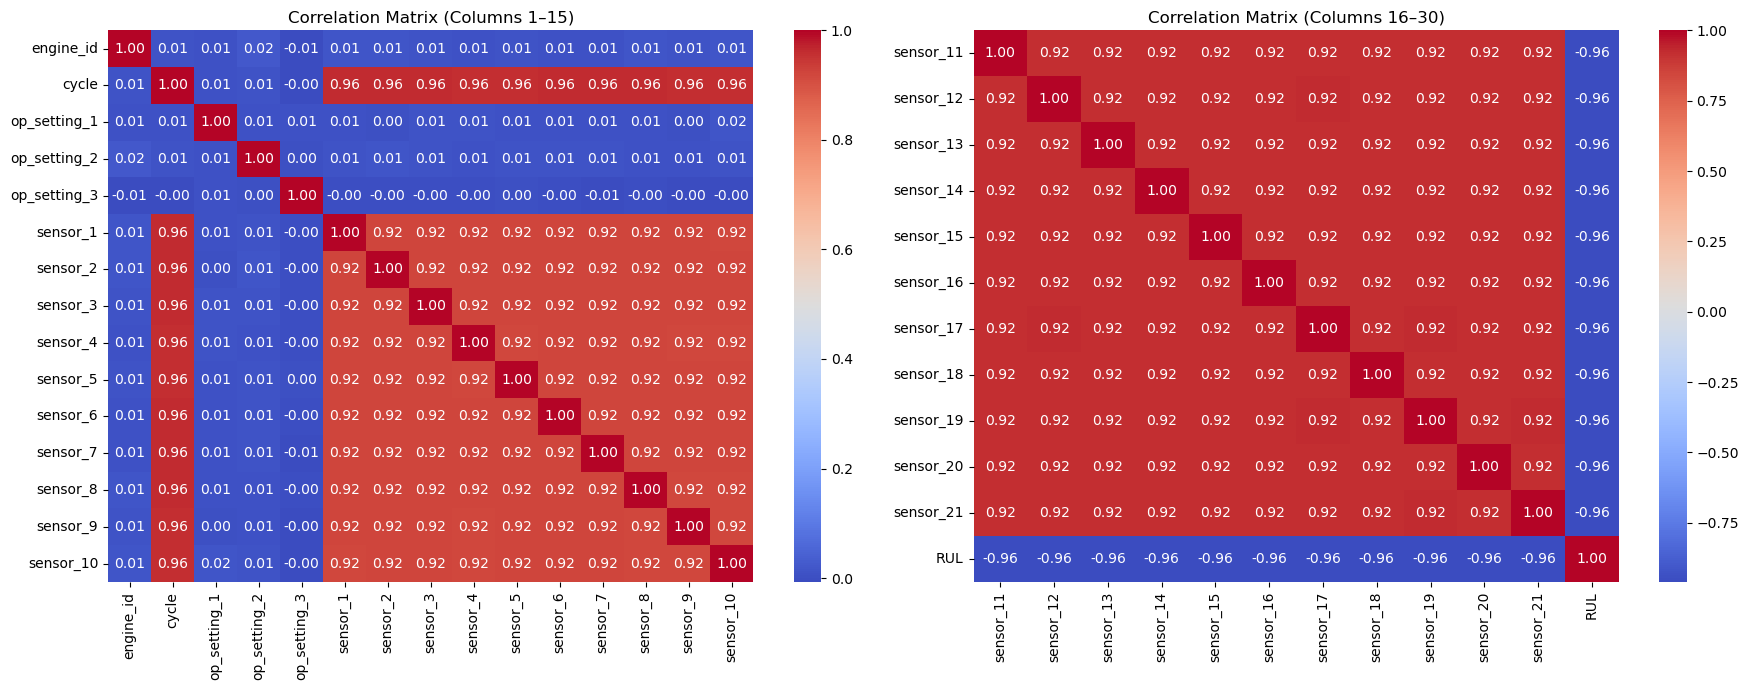

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Select numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

# Split into two groups: 1–15 and 16–30
group1 = numerical_cols[:15]
group2 = numerical_cols[15:30]

# Compute correlation matrix
correlation_matrix = df[numerical_cols].corr()

# Extract sub-matrices for each group
matrix1 = correlation_matrix.loc[group1, group1]
matrix2 = correlation_matrix.loc[group2, group2]

# Plot two heatmaps side by side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(matrix1, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0])
axes[0].set_title("Correlation Matrix (Columns 1–15)")

sns.heatmap(matrix2, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title("Correlation Matrix (Columns 16–30)")

plt.tight_layout()
plt.show()


In [16]:
df.dtypes

engine_id         int64
cycle             int64
op_setting_1    float64
op_setting_2    float64
op_setting_3    float64
sensor_1        float64
sensor_2        float64
sensor_3        float64
sensor_4        float64
sensor_5        float64
sensor_6        float64
sensor_7        float64
sensor_8        float64
sensor_9        float64
sensor_10       float64
sensor_11       float64
sensor_12       float64
sensor_13       float64
sensor_14       float64
sensor_15       float64
sensor_16       float64
sensor_17       float64
sensor_18       float64
sensor_19       float64
sensor_20       float64
sensor_21       float64
RUL               int64
dtype: object

# # Data splitting

In [4]:
x=df.drop(columns='RUL')
y=df['RUL']

In [9]:
y.value_counts()

RUL
1      92
18     51
268    50
149    48
162    47
       ..
299    17
302    13
301     9
303     6
304     4
Name: count, Length: 304, dtype: int64

# # APPLYING SMOTE TO BALANCE THE DATA

In [5]:

from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=1)

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((7000, 26), (3000, 26), (7000,), (3000,))

In [18]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_regression

# Select top 12 features based on mutual information for regression tasks
select_12_columns = SelectKBest(mutual_info_regression, k=12)
select_12_columns.fit(x_train, y_train)

# Get the selected feature names
x_train.columns[select_12_columns.get_support()]


Index(['cycle', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7',
       'sensor_8', 'sensor_12', 'sensor_14', 'sensor_15', 'sensor_18',
       'sensor_19'],
      dtype='object')

In [6]:
x_train=x_train[['cycle', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7',
       'sensor_8', 'sensor_12', 'sensor_14', 'sensor_15', 'sensor_18',
       'sensor_19']]

for column in x_train:
    print(f"Value counts for {column}:")
    print(df[column].value_counts())
    print('-' * 50)


Value counts for cycle:
cycle
132    53
122    52
128    50
86     49
7      49
       ..
55     21
23     21
83     20
18     20
253    19
Name: count, Length: 300, dtype: int64
--------------------------------------------------
Value counts for sensor_1:
sensor_1
0.857993    1
0.530322    1
0.661421    1
0.143152    1
0.329296    1
           ..
0.421278    1
0.575679    1
0.523521    1
0.594825    1
0.677848    1
Name: count, Length: 10000, dtype: int64
--------------------------------------------------
Value counts for sensor_2:
sensor_2
0.768476    1
0.721244    1
0.741925    1
0.297664    1
0.322162    1
           ..
0.419505    1
0.608126    1
0.522165    1
0.814566    1
0.662365    1
Name: count, Length: 10000, dtype: int64
--------------------------------------------------
Value counts for sensor_3:
sensor_3
1.049654    1
0.654854    1
0.752179    1
0.302548    1
0.336295    1
           ..
0.502491    1
0.697982    1
0.504987    1
0.749985    1
0.524135    1
Name: count, Len

In [7]:

x_test=x_test[['cycle', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7',
       'sensor_8', 'sensor_12', 'sensor_14', 'sensor_15', 'sensor_18',
       'sensor_19']]
for column in x_test:
    print(f"Value counts for {column}:")
    print(df[column].value_counts())
    print('-' * 50)


Value counts for cycle:
cycle
132    53
122    52
128    50
86     49
7      49
       ..
55     21
23     21
83     20
18     20
253    19
Name: count, Length: 300, dtype: int64
--------------------------------------------------
Value counts for sensor_1:
sensor_1
0.857993    1
0.530322    1
0.661421    1
0.143152    1
0.329296    1
           ..
0.421278    1
0.575679    1
0.523521    1
0.594825    1
0.677848    1
Name: count, Length: 10000, dtype: int64
--------------------------------------------------
Value counts for sensor_2:
sensor_2
0.768476    1
0.721244    1
0.741925    1
0.297664    1
0.322162    1
           ..
0.419505    1
0.608126    1
0.522165    1
0.814566    1
0.662365    1
Name: count, Length: 10000, dtype: int64
--------------------------------------------------
Value counts for sensor_3:
sensor_3
1.049654    1
0.654854    1
0.752179    1
0.302548    1
0.336295    1
           ..
0.502491    1
0.697982    1
0.504987    1
0.749985    1
0.524135    1
Name: count, Len

In [21]:
x_train_df = pd.DataFrame(x_train)
x_train_df.to_csv('x_train.csv', index=False)

# ALGORITHM IMPLEMENTATION

In [22]:
# Import necessary libraries
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the Random Forest Regressor model
rf_model = RandomForestRegressor()

# Train the model using the training data
rf_model.fit(x_train, y_train)

# Make predictions on the test data
y_pred_rf = rf_model.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Output the performance metrics
print(f"Random Forest Model Performance:")
print(f"Mean Squared Error (MSE): {mse_rf:.4f}")
print(f"R^2 Score: {r2_rf:.4f}")


Random Forest Model Performance:
Mean Squared Error (MSE): 11.1807
R^2 Score: 0.9985


In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
import shap
import matplotlib.pyplot as plt

# ----------------------------
# Initialize base Random Forest
# ----------------------------
rf_model = RandomForestRegressor(random_state=42)

# ----------------------------
# Define hyperparameter grid
# ----------------------------
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 50],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["auto", "sqrt", "log2"]
}

# ----------------------------
# Randomized Search CV
# ----------------------------
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist,
    n_iter=20,          # number of random combinations to try
    cv=3,               # 3-fold cross validation
    verbose=2,
    n_jobs=-1,
    random_state=42,
    scoring="neg_mean_squared_error"
)

# Fit the model on training data
random_search.fit(x_train, y_train)

# Best model
best_rf = random_search.best_estimator_
print("✅ Best Hyperparameters:", random_search.best_params_)

# ----------------------------
# Predictions with tuned model
# ----------------------------
y_pred_rf = best_rf.predict(x_test)

# Evaluate performance
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("\n📊 Random Forest Model Performance (Tuned):")
print(f"Mean Squared Error (MSE): {mse_rf:.4f}")
print(f"R^2 Score: {r2_rf:.4f}")

# ----------------------------
# SHAP Interpretability
# ----------------------------
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(x_test)

# Summary Plot (Global Feature Importance)
shap.summary_plot(shap_values, x_test, feature_names=x_test.columns)

# Bar Plot for feature importance
shap.summary_plot(shap_values, x_test, plot_type="bar", feature_names=x_test.columns)

# Dependence Plot for top feature (optional)
top_feature = x_test.columns[np.argsort(np.abs(shap_values).mean(0))[-1]]
shap.dependence_plot(top_feature, shap_values, x_test, feature_names=x_test.columns)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


C:\Users\1005\AppData\Roaming\Python\Python311\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
12 fits failed out of a total of 60.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\1005\AppData\Roaming\Python\Python311\site-packages\sklearn\model_selection\_validation.py", line 729, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\1005\AppData\Roaming\Python\Python311\site-packages\sklearn\base.py", line 1145, in wrapper
    estimator._validate_params()
  File "C:\Users\1005\AppData\Roaming\Python\Python311\site-packages\sklearn\base.py", line 638, in _validate_params
    validate_par

✅ Best Hyperparameters: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}

📊 Random Forest Model Performance (Tuned):
Mean Squared Error (MSE): 15.8354
R^2 Score: 0.9978


In [23]:
import joblib 

joblib.dump(rf_model, "RF.joblib")

['RF.joblib']

In [25]:
# Import necessary libraries
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the Extra Trees Regressor model
extra_tree_model = ExtraTreesRegressor()

# Train the model using the training data
extra_tree_model.fit(x_train, y_train)

# Make predictions on the test data
y_pred_et = extra_tree_model.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_et = mean_squared_error(y_test, y_pred_et)
r2_et = r2_score(y_test, y_pred_et)

# Output the performance metrics
print(f"Extra Tree Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_et:.4f}")
print(f"R^2 Score: {r2_et:.4f}")


Extra Tree Regressor Performance:
Mean Squared Error (MSE): 10.9384
R^2 Score: 0.9985


Extra Trees Regressor Performance:
Mean Squared Error (MSE): 10.8840
R^2 Score: 0.9985
🔹 SHAP Summary Plot


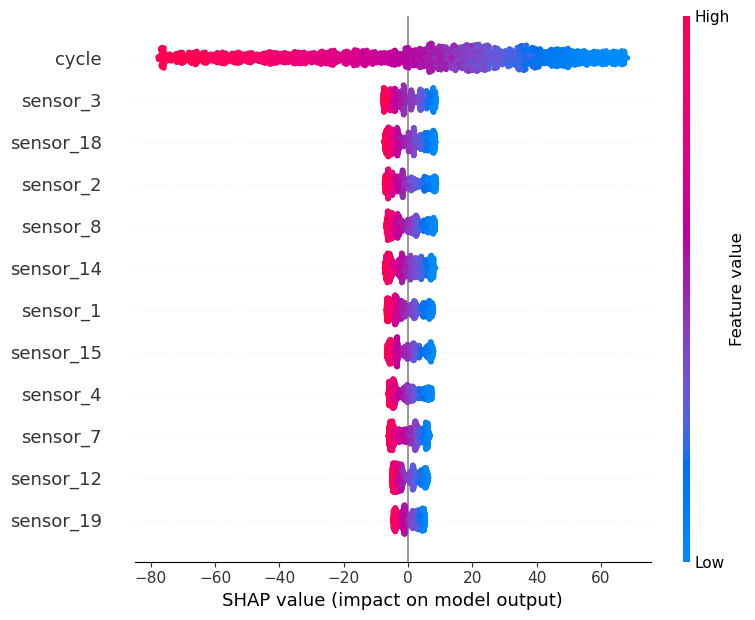

🔹 SHAP Bar Plot (Feature Importance)


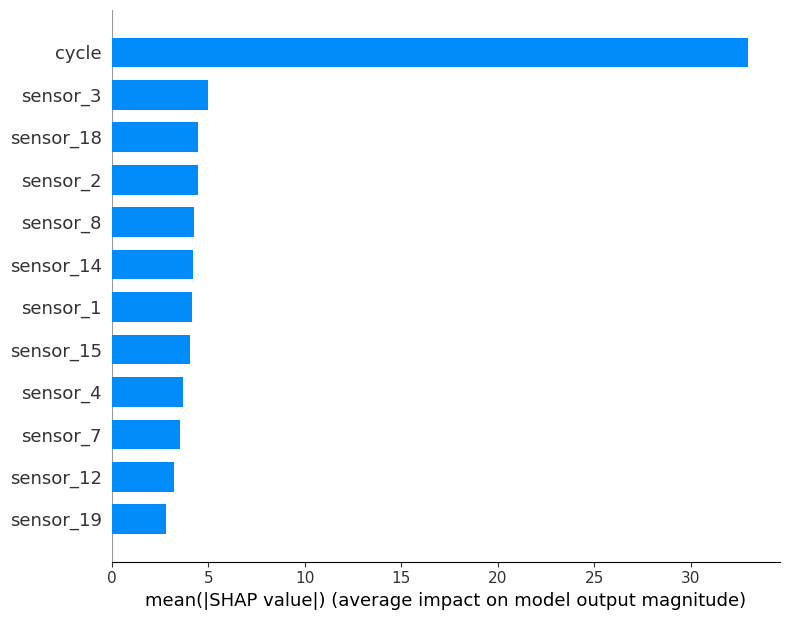

🔹 SHAP Dependence Plot for top feature: cycle


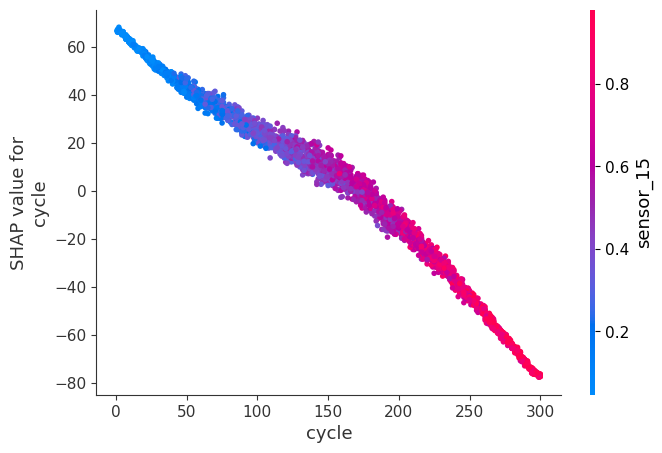

In [9]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, r2_score
import shap
import matplotlib.pyplot as plt

# ----------------------------
# Initialize Extra Trees Regressor
# ----------------------------
extra_tree_model = ExtraTreesRegressor(random_state=42)

# Train the model
extra_tree_model.fit(x_train, y_train)

# Predictions
y_pred_et = extra_tree_model.predict(x_test)

# Evaluate performance
mse_et = mean_squared_error(y_test, y_pred_et)
r2_et = r2_score(y_test, y_pred_et)

print(f"Extra Trees Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_et:.4f}")
print(f"R^2 Score: {r2_et:.4f}")

# ----------------------------
# Explainable AI with SHAP
# ----------------------------
# Create TreeExplainer for ExtraTrees
explainer = shap.TreeExplainer(extra_tree_model)
shap_values = explainer.shap_values(x_test)

# Global Feature Importance - Summary Plot
print("🔹 SHAP Summary Plot")
shap.summary_plot(shap_values, x_test, feature_names=x_test.columns)

# Bar Plot (average impact of features)
print("🔹 SHAP Bar Plot (Feature Importance)")
shap.summary_plot(shap_values, x_test, plot_type="bar", feature_names=x_test.columns)

# Example: Dependence plot for the most important feature
top_feature = x_test.columns[np.argsort(np.abs(shap_values).mean(0))[-1]]
print(f"🔹 SHAP Dependence Plot for top feature: {top_feature}")
shap.dependence_plot(top_feature, shap_values, x_test, feature_names=x_test.columns)


In [26]:
import joblib 

joblib.dump(extra_tree_model, "ET.joblib")

['ET.joblib']

In [8]:
# Import necessary libraries
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import mean_squared_error, r2_score

# ----------------------------
# Define Feedforward Neural Network (FNN)
# ----------------------------
fnn_model = Sequential([
    Dense(64, activation='relu', input_shape=(x_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)  # Regression output
])

# Compile model
fnn_model.compile(optimizer='adam', loss='mse')

# Train model
fnn_model.fit(x_train, y_train, epochs=50, batch_size=32, verbose=0)

# Predictions
y_pred_fnn = fnn_model.predict(x_test)

# Evaluate model
mse_fnn = mean_squared_error(y_test, y_pred_fnn)
r2_fnn = r2_score(y_test, y_pred_fnn)

print("Feedforward Neural Network (FNN) Performance:")
print(f"Mean Squared Error (MSE): {mse_fnn:.4f}")
print(f"R^2 Score: {r2_fnn:.4f}")






94/94 [==============================] - 0s 2ms/step
Feedforward Neural Network (FNN) Performance:
Mean Squared Error (MSE): 17.8211
R^2 Score: 0.9976


In [9]:
# Import necessary libraries
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ----------------------------
# Initialize MLP Regressor
# ----------------------------
mlp_model = MLPRegressor(hidden_layer_sizes=(100, 50), 
                         activation='relu', solver='adam',
                         max_iter=500, random_state=42)

# Train the model
mlp_model.fit(x_train, y_train)

# Predictions
y_pred_mlp = mlp_model.predict(x_test)

# Evaluate model
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
r2_mlp = r2_score(y_test, y_pred_mlp)

print("Multi-Layer Perceptron (MLP) Performance:")
print(f"Mean Squared Error (MSE): {mse_mlp:.4f}")
print(f"R^2 Score: {r2_mlp:.4f}")


Multi-Layer Perceptron (MLP) Performance:
Mean Squared Error (MSE): 12.0854
R^2 Score: 0.9984


In [27]:
# Import necessary libraries
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the Decision Tree Regressor model
dt_regressor = DecisionTreeRegressor()

# Train the model using the training data
dt_regressor.fit(x_train, y_train)

# Make predictions on the test data
y_pred_dt = dt_regressor.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# Output the performance metrics
print(f"Decision Tree Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_dt:.4f}")
print(f"R^2 Score: {r2_dt:.4f}")


Decision Tree Regressor Performance:
Mean Squared Error (MSE): 21.2120
R^2 Score: 0.9971


In [10]:
# Import necessary libraries
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the K-Nearest Neighbors Regressor model
knn_regressor = KNeighborsRegressor(n_neighbors=5)  # You can adjust n_neighbors

# Train the model using the training data
knn_regressor.fit(x_train, y_train)

# Make predictions on the test data
y_pred_knn = knn_regressor.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)

# Output the performance metrics
print("K-Nearest Neighbors Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_knn:.4f}")
print(f"R^2 Score: {r2_knn:.4f}")


K-Nearest Neighbors Regressor Performance:
Mean Squared Error (MSE): 12.1475
R^2 Score: 0.9984


In [28]:
# Import necessary libraries
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the Gradient Boosting Regressor model
gb_regressor = GradientBoostingRegressor()

# Train the model using the training data
gb_regressor.fit(x_train, y_train)

# Make predictions on the test data
y_pred_gb = gb_regressor.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_gb = mean_squared_error(y_test, y_pred_gb)
r2_gb = r2_score(y_test, y_pred_gb)

# Output the performance metrics
print(f"Gradient Boosting Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_gb:.4f}")
print(f"R^2 Score: {r2_gb:.4f}")


Gradient Boosting Regressor Performance:
Mean Squared Error (MSE): 10.6522
R^2 Score: 0.9986


In [58]:
# Import necessary libraries
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the XGBoost Regressor model
xgb_regressor = xgb.XGBRegressor()

# Train the model using the training data
xgb_regressor.fit(x_train, y_train)

# Make predictions on the test data
y_pred_xgb = xgb_regressor.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

# Output the performance metrics
print(f"XGBoost Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_xgb:.4f}")
print(f"R^2 Score: {r2_xgb:.4f}")


XGBoost Regressor Performance:
Mean Squared Error (MSE): 0.0029
R^2 Score: 0.9984


In [59]:
# Import necessary libraries
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the K-Nearest Neighbors Regressor model
knn_regressor = KNeighborsRegressor()

# Train the model using the training data
knn_regressor.fit(x_train, y_train)

# Make predictions on the test data
y_pred_knn = knn_regressor.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)

# Output the performance metrics
print(f"K-Nearest Neighbors Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_knn:.4f}")
print(f"R^2 Score: {r2_knn:.4f}")


K-Nearest Neighbors Regressor Performance:
Mean Squared Error (MSE): 0.0101
R^2 Score: 0.9944


In [8]:
# Import necessary libraries
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the LightGBM Regressor model
lgb_model = lgb.LGBMRegressor()

# Train the model using the training data
lgb_model.fit(x_train, y_train)

# Make predictions on the test data
y_pred_lgb = lgb_model.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_lgb = mean_squared_error(y_test, y_pred_lgb)
r2_lgb = r2_score(y_test, y_pred_lgb)

# Output the performance metrics
print("LightGBM Model Performance:")
print(f"Mean Squared Error (MSE): {mse_lgb:.4f}")
print(f"R^2 Score: {r2_lgb:.4f}")


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000498 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3046
[LightGBM] [Info] Number of data points in the train set: 7000, number of used features: 12
[LightGBM] [Info] Start training from score 149.281143
LightGBM Model Performance:
Mean Squared Error (MSE): 10.8263
R^2 Score: 0.9985


In [9]:
# Import necessary libraries
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.metrics import mean_squared_error, r2_score

# Reshape input data for LSTM [samples, timesteps, features]
# Here we assume each feature is one timestep. Adjust timesteps if needed.
x_train_lstm = np.expand_dims(x_train, axis=1)
x_test_lstm = np.expand_dims(x_test, axis=1)

# Initialize the LSTM model
lstm_model = Sequential()
lstm_model.add(LSTM(units=64, activation='tanh', input_shape=(x_train_lstm.shape[1], x_train_lstm.shape[2])))
lstm_model.add(Dense(1))  # Output layer for regression

# Compile the model
lstm_model.compile(optimizer='adam', loss='mse')

# Train the model
lstm_model.fit(x_train_lstm, y_train, epochs=20, batch_size=32, verbose=1)

# Make predictions
y_pred_lstm = lstm_model.predict(x_test_lstm).flatten()

# Evaluate the model
mse_lstm = mean_squared_error(y_test, y_pred_lstm)
r2_lstm = r2_score(y_test, y_pred_lstm)

# Output the performance metrics
print("LSTM Model Performance:")
print(f"Mean Squared Error (MSE): {mse_lstm:.4f}")
print(f"R^2 Score: {r2_lstm:.4f}")





Epoch 1/20

219/219 [==============================] - 3s 3ms/step - loss: 27922.2461
Epoch 2/20
219/219 [==============================] - 1s 2ms/step - loss: 23678.2422
Epoch 3/20
219/219 [==============================] - 1s 3ms/step - loss: 20530.4961
Epoch 4/20
219/219 [==============================] - 1s 2ms/step - loss: 18127.9004
Epoch 5/20
219/219 [==============================] - 1s 3ms/step - loss: 16153.3203
Epoch 6/20
219/219 [==============================] - 1s 3ms/step - loss: 14489.4873
Epoch 7/20
219/219 [==============================] - 1s 3ms/step - loss: 13088.7363
Epoch 8/20
219/219 [==============================] - 1s 2ms/step - loss: 11912.5967
Epoch 9/20
219/219 [==============================] - 1s 2ms/step - loss: 10930.7910
Epoch 10/20
219/219 [==============================] - 1s 2ms/step - loss: 10122.1943
Epoch 11/20
219/219 [==============================] - 1s 2ms/step - loss: 9465.5430
Epoch 12/20
219/219 [==============================] - 1s 3m

In [60]:
# Import necessary libraries
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the Support Vector Regressor model
svr_model = SVR()

# Train the model using the training data
svr_model.fit(x_train, y_train)

# Make predictions on the test data
y_pred_svr = svr_model.predict(x_test)

# Evaluate the model performance using Mean Squared Error (MSE) and R^2 score
mse_svr = mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)

# Output the performance metrics
print(f"Support Vector Regressor Performance:")
print(f"Mean Squared Error (MSE): {mse_svr:.4f}")
print(f"R^2 Score: {r2_svr:.4f}")


Support Vector Regressor Performance:
Mean Squared Error (MSE): 0.0079
R^2 Score: 0.9956


In [29]:
import pandas as pd
import numpy as np
import joblib

# ----------------------------
# Load model
# ----------------------------
model = joblib.load("ET.joblib")   # make sure ET.joblib is in the same folder
print("✅ Loaded trained model from ET.joblib")

# ----------------------------
# Load x_train data
# ----------------------------
X_train = pd.read_csv("x_train.csv")

# ----------------------------
# Predict first 50 inputs
# ----------------------------
N = min(50, X_train.shape[0])
X_first = X_train.iloc[:N]
y_pred_first = model.predict(X_first)

# ----------------------------
# Classify predictions
# ----------------------------
def classify_rul(rul):
    if rul <= 30:
        return "CRITICAL"
    elif rul <= 100:
        return "WARNING"
    else:
        return "NORMAL"

status = [classify_rul(p) for p in y_pred_first]

# Suggestions
suggestion_map = {
    "CRITICAL": "⚠️ Immediate inspection & maintenance required. Ground the engine and run diagnostics.",
    "WARNING": "🔧 Schedule maintenance soon. Increase monitoring and prepare spare parts.",
    "NORMAL": "✅ Engine is healthy. Continue regular monitoring."
}
suggestions = [suggestion_map[s] for s in status]

# ----------------------------
# Build results table
# ----------------------------
results = pd.DataFrame({
    "pred_RUL": np.round(y_pred_first, 2),
    "status": status,
    "suggestion": suggestions
})

print("\n📊 First 50 Predictions with Suggestions:")
print(results.to_string(index=False))

# Optionally save
results.to_csv("rul_predictions_first_50.csv", index=False)
print("\n✅ Results saved to 'rul_predictions_first_50.csv'")


✅ Loaded trained model from ET.joblib

📊 First 50 Predictions with Suggestions:
 pred_RUL   status                                                                             suggestion
     93.0  WARNING              🔧 Schedule maintenance soon. Increase monitoring and prepare spare parts.
    261.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
    228.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
    287.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
    264.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
     46.0  WARNING              🔧 Schedule maintenance soon. Increase monitoring and prepare spare parts.
    163.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
    148.0   NORMAL                                      ✅ Engine is heal

In [30]:
import pandas as pd
import numpy as np
import joblib

# ----------------------------
# Load model
# ----------------------------
model = joblib.load("ET.joblib")   # make sure ET.joblib is in the same folder
print("✅ Loaded trained model from ET.joblib")

# ----------------------------
# Load x_train data
# ----------------------------
X_train = pd.read_csv("x_train.csv")

# ----------------------------
# Predict first 50 inputs
# ----------------------------
N = min(50, X_train.shape[0])
X_first = X_train.iloc[:N]
y_pred_first = model.predict(X_first)

# ----------------------------
# Classify predictions
# ----------------------------
def classify_rul(rul):
    if rul <= 30:
        return "CRITICAL"
    elif rul <= 100:
        return "WARNING"
    else:
        return "NORMAL"

status = [classify_rul(p) for p in y_pred_first]

# Suggestions
suggestion_map = {
    "CRITICAL": "⚠️ Immediate inspection & maintenance required. Ground the engine and run diagnostics.",
    "WARNING": "🔧 Schedule maintenance soon. Increase monitoring and prepare spare parts.",
    "NORMAL": "✅ Engine is healthy. Continue regular monitoring."
}
suggestions = [suggestion_map[s] for s in status]

# ----------------------------
# Build results table
# ----------------------------
results = pd.DataFrame({
    "Row": range(1, N+1),   # row numbers 1–50
    "pred_RUL": np.round(y_pred_first, 2),
    "status": status,
    "suggestion": suggestions
})

print("\n📊 First 50 Predictions with Suggestions:")
print(results.to_string(index=False))

# Optionally save
results.to_csv("rul_predictions_first_50.csv", index=False)
print("\n✅ Results saved to 'rul_predictions_first_50.csv'")


✅ Loaded trained model from ET.joblib

📊 First 50 Predictions with Suggestions:
 Row  pred_RUL   status                                                                             suggestion
   1      93.0  WARNING              🔧 Schedule maintenance soon. Increase monitoring and prepare spare parts.
   2     261.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
   3     228.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
   4     287.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
   5     264.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
   6      46.0  WARNING              🔧 Schedule maintenance soon. Increase monitoring and prepare spare parts.
   7     163.0   NORMAL                                      ✅ Engine is healthy. Continue regular monitoring.
   8     148.0   NORMAL         

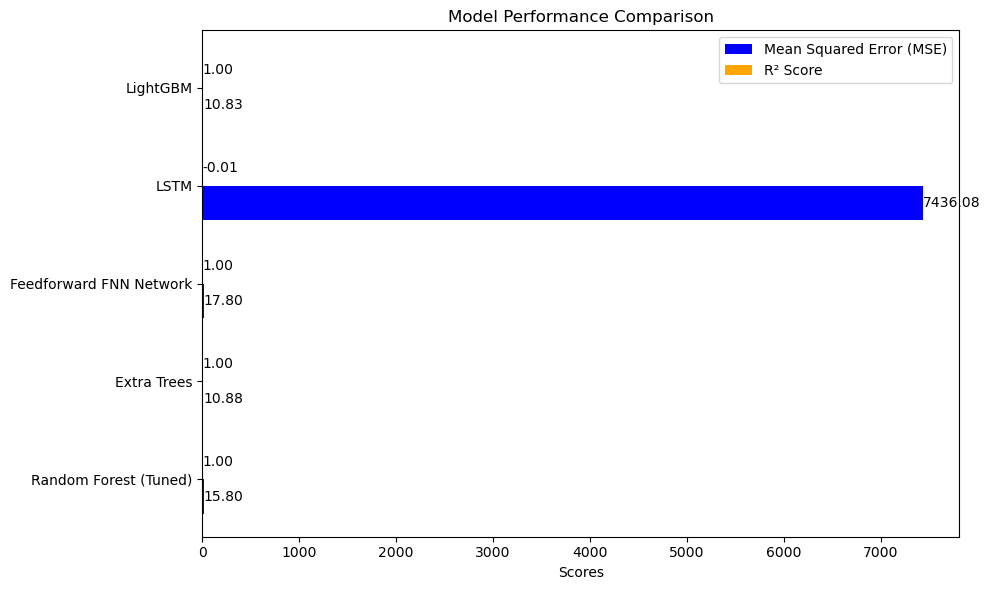

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Data for the models
models = ['Random Forest (Tuned)', 'Extra Trees', 'Feedforward FNN Network', 'LSTM', 'LightGBM']
mse = [15.8, 10.8840, 17.8, 7436.0781, 10.8263]
r2_score = [0.9985, 0.9985, 0.9976, -0.0100, 0.9985]

# Create a figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Bar width and positions
bar_width = 0.35
index = np.arange(len(models))

# Plotting the horizontal bars for MSE and R² Score
ax.barh(index, mse, bar_width, label='Mean Squared Error (MSE)', color='blue')
ax.barh(index + bar_width, r2_score, bar_width, label='R² Score', color='orange')

# Labeling the bars
for i, bar in enumerate(ax.patches[:len(mse)]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2, f'{bar.get_width():.2f}', 
            va='center', color='black')

for i, bar in enumerate(ax.patches[len(mse):]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2, f'{bar.get_width():.2f}', 
            va='center', color='black')

# Adding labels, title, and custom y-axis tick labels
ax.set_yticks(index + bar_width / 2)
ax.set_yticklabels(models)
ax.set_xlabel('Scores')
ax.set_title('Model Performance Comparison')

# Adding legend
ax.legend()

# Show the plot
plt.tight_layout()
plt.show()